# The VGG16 model was developed by the Visual Graphics Group (VGG)

# By default, the VGG-16 model expects color input images to be rescaled to the size of 224 X 224 squares.

In [1]:
import numpy as  np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.applications.vgg16 import VGG16

In [2]:
#load model
model = VGG16(include_top=False, input_shape=(224, 224, 3))
model.summary()

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 14,714,688 (56.13 MB)

 Non-trainable params: 0 (0.00 B)

# 1. The dataset needs to be loaded and the images need to be reshaped to 224 x 224 image size.  

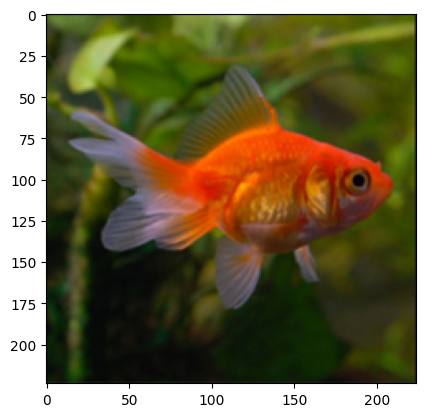

In [4]:
from tensorflow.keras.preprocessing.image import load_img
from tensorflow.keras.applications.imagenet_utils import preprocess_input
import numpy as np
import matplotlib.pyplot as plt

#load an image
image = load_img('c:\d\goldfish.jpg', target_size=(224,224))

#convert the image pixels to a numpy array
image = np.array(image)

#reshap the data for the model
image = image.reshape((1, image.shape[1], image.shape[1],image.shape[2]))

#prepare the image for the VGG model
image = preprocess_input(image)
image

my_image = plt.imread('c:\d\goldfish.jpg')
plt.imshow(my_image)


# 2. The model can be loaded and a predicton made.

This means that a predicted probability of the photo belonging to each of the 1,000 classes is made. In this example, we are only concerned with the most likely class, so we can decode the predictions and retrieve the label or name of the class with the highest probability

In [5]:
# predict the probability across all output classes
pred = model. predict(image)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 249ms/step


In [9]:
from tensorflow.keras.applications.vgg16 import VGG16, decode_predictions

# Load the VGG16 model with the top layers included
model = VGG16(include_top=True, input_shape=(224, 224, 3))

# Predict the probability across all output classes
pred = model.predict(image)

# Decode the predictions
label = decode_predictions(pred, top=1)  # Only the top prediction

# Display the result
for i in label[0]:
    print(f"Predicted label: {i[1]} with probability {i[2]:.2f}")


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 176ms/step
35363/35363 ━━━━━━━━━━━━━━━━━━━━ 0s 3us/step
Predicted label: goldfish with probability 1.00


# 3. Prepare our own data

Load flowers dataset

In [35]:
import pathlib

# Manually set up the dictionary with your image path
flowers_images_dict = {
    'roses': [pathlib.Path('c:\d\roses.jpg')],  # Replace with the path of your flower image
    'daisy': [],
    'dandelion': [],
    'sunflowers': [],
    'tulips': [],
}

# Now you can access the first rose image path without an IndexError
first_rose_image_path = flowers_images_dict['roses'][0]
print(f"The path to the first rose image is: {first_rose_image_path}")


oses.jpg to the first rose image is: c:\d


In [36]:
list(data_dir.glob('*/*.jpg'))[:5]

[WindowsPath('c:/d/Acer Before Sell/1.jpg'),
 WindowsPath('c:/d/Acer Before Sell/2.jpg'),
 WindowsPath('c:/d/Acer Before Sell/20240104_171139.jpg'),
 WindowsPath('c:/d/Acer Before Sell/20240104_171349.jpg'),
 WindowsPath('c:/d/Acer Before Sell/20240104_171503.jpg')]

Read flowers images from disk into numpy array using opencv

In [37]:
import pathlib

# Define the directory where your flower images are located
data_dir = pathlib.Path('c:\\d\\')

# Check the list of images in the roses directory
roses_images = list(data_dir.glob('roses/*'))
print(f"Number of rose images found: {len(roses_images)}")
print("Rose images paths:", roses_images)

# If images are found, access the first image
if roses_images:
    first_rose_image_path = str(roses_images[0])
    print(f"The path to the first rose image is: {first_rose_image_path}")
else:
    print("No rose images found in the specified directory.")


Number of rose images found: 0
Rose images paths: []
No rose images found in the specified directory.


In [38]:
str(flowers_images_dict['roses'][0])

'c:\\d\roses.jpg'

In [45]:
# Import necessary libraries
import pathlib
import cv2

# Define the directory where your flower images are located
data_dir = pathlib.Path('c:\\d\\')  # Make sure this path is correct

# Create the flowers_images_dict with the path to the rose image
flowers_images_dict = {
    'roses': [data_dir / 'roses.jpg'],  # Replace 'roses.jpg' with your actual image file name
    'daisy': [],
    'dandelion': [],
    'sunflowers': [],
    'tulips': [],
}

# Read the first rose image using OpenCV
img = cv2.imread(str(flowers_images_dict['roses'][0]))

# Check if the image was successfully loaded and print its shape
if img is not None:
    print("Image shape:", img.shape)  # This will print the dimensions of the image
else:
    print("Image not found. Please check the file path and name.")

# Optional: Display the image using OpenCV (this will open a window)
cv2.imshow("Rose Image", img)
cv2.waitKey(0)  # Wait for a key press to close the window
cv2.destroyAllWindows()  # Close the window after the key press


Image shape: (735, 832, 3)


In [50]:
resized_img = cv2.resize(img, (224, 224))
print(resized_img.shape)


(224, 224, 3)


In [60]:
import cv2

X, y = [], []

print("Loading images...")
for flower_name, images in flowers_images_dict.items():
    print(f"{flower_name} images to load: {len(images)}")
    for image in images:
        img = cv2.imread(str(image))
        if img is None:
            print(f"Warning: Could not load image {image}. Skipping...")
            continue
        resized_img = cv2.resize(img, (224, 224))
        X.append(resized_img)
        y.append(flowers_labels_dict[flower_name])

# Convert lists to numpy arrays after loading images
X = np.array(X)
y = np.array(y)

# Check the total number of images loaded and labels created
print(f"Total images loaded: {len(X)}")
print(f"Total labels loaded: {len(y)}")


Loading images...
roses images to load: 1
daisy images to load: 0
dandelion images to load: 0
sunflowers images to load: 0
tulips images to load: 0
Total images loaded: 1
Total labels loaded: 1


In [61]:
X = np.array(X)
y = np.array(y)

Train test split

In [62]:
from sklearn.model_selection import train_test_split
import numpy as np

# Ensure X and y are numpy arrays and have more than one sample
X = np.array(X)
y = np.array(y)

if len(X) > 1:
    # Proceed with the split if you have enough samples
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=1
    )

    X_train, X_val, y_train, y_val = train_test_split(
        X_train, y_train, test_size=0.25, random_state=1
    )

    print("Training set shape:", X_train.shape, y_train.shape)
    print("Validation set shape:", X_val.shape, y_val.shape)
    print("Test set shape:", X_test.shape, y_test.shape)
else:
    print("Not enough samples to perform a train-test split. Add more images.")


Not enough samples to perform a train-test split. Add more images.


Representing Labels using one-hot-encoding

In [84]:
# Import necessary libraries
import numpy as np
import cv2  # Ensure OpenCV is imported for image handling
from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import to_categorical

# Example: Define your dictionaries with flower names and image paths
flowers_images_dict = {
    'roses': ['c:\\d\\roses.jpg', 'c:\\d\\roses2.jpg'],  # Add your actual paths here
    'daisy': ['c:\\d\\daisy.jpg', 'c:\\d\\daisy1.jpg'],
    'dandelion': [],
    'sunflowers': [],
    'tulips': []
}

flowers_labels_dict = {
    'roses': 0,
    'daisy': 1,
    'dandelion': 2,
    'sunflowers': 3,
    'tulips': 4
}

# Initialize empty lists for images and labels
X, y = [], []

# Load your images and labels
print("Loading images and labels...")
for flower_name, images in flowers_images_dict.items():
    print(f"Flower: {flower_name}, Number of images: {len(images)}")
    for image in images:
        img = cv2.imread(str(image))
        if img is not None:  # Check if the image was loaded correctly
            resized_img = cv2.resize(img, (224, 224))  # Resize image to desired dimensions
            X.append(resized_img)
            y.append(flowers_labels_dict[flower_name])
        else:
            print(f"Warning: Image {image} could not be loaded.")

# Convert lists to numpy arrays
X = np.array(X)
y = np.array(y)

# Check the lengths of X and y
print(f"Number of images in X: {len(X)}")
print(f"Number of labels in y: {len(y)}")

# Check if there are at least 2 samples
if len(X) < 2 or len(y) < 2:
    print("Not enough images and labels for splitting. Found:")
    print(f"Images: {len(X)}, Labels: {len(y)}")
    raise ValueError("`X` and `y` must contain at least two samples for train-test split.")

# Determine a safe test size based on the sample count
test_size = 0.2 if len(X) > 5 else 0.5

# Perform the train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_size, random_state=1)

# Further split the training set into train and validation sets if large enough
if len(X_train) > 1:
    X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.25, random_state=1)
else:
    print("Not enough data to create a validation set. Validation set skipped.")
    X_val, y_val = np.array([]), np.array([])

# Define `k` as the number of unique classes in `y` for one-hot encoding
k = np.unique(y).size

# Perform one-hot encoding
Y_oh_train = to_categorical(y_train, k)
Y_oh_val = to_categorical(y_val, k) if len(y_val) > 0 else np.array([])
Y_oh_test = to_categorical(y_test, k)

# Displaying the first few encoded labels to confirm
print('First 5 elements of y_train:', y_train[:5])
print('\nFirst 5 elements of Y_oh_train:')
print(Y_oh_train[:5])


Loading images and labels...
Flower: roses, Number of images: 2
Flower: daisy, Number of images: 2
Flower: dandelion, Number of images: 0
Flower: sunflowers, Number of images: 0
Flower: tulips, Number of images: 0
Number of images in X: 4
Number of labels in y: 4
First 5 elements of y_train: [0]

First 5 elements of Y_oh_train:
[[1. 0.]]


Preprocessing: scale images

In [85]:
X_train_scaled = X_train / 255
X_val_scaled = X_val /255
X_test_scaled = X_test / 255

# 4. VGGNET With Keras on Custom Dataset

In [86]:
from tensorflow.keras.layers import Input
from tensorflow.keras.layers import Conv2D
from tensorflow.keras.layers import MaxPool2D
from tensorflow.keras.layers import Flatten
from tensorflow.keras.layers import Dense
from tensorflow.keras.models import Model

def Custom_VGG(classes, input_tensor = None):
    
    img_rows, img_cols = 224, 224
    img_channels = 3
    
    img_dim = (img_rows, img_cols, img_channels)
    img_input = Input(shape=img_dim)
    
    #Block 1
    x = Conv2D(64, (3,3), activation = 'relu', padding='same', name='block1_conv1')(img_input)
    x = Conv2D(64, (3,3), activation = 'relu', padding='same', name='block1_conv2')(x)
    x = MaxPool2D((2,2),strides=(2,2),name = 'block1_pool')(x)
    
    #Block 2
    x = Conv2D(128, (3,3), activation = 'relu', padding='same', name='block2_conv1')(x)
    x = Conv2D(128, (3,3), activation = 'relu', padding='same', name='block2_conv2')(x)
    x = MaxPool2D((2,2),strides=(2,2),name = 'block2_pool')(x)
    
    #Block 3
    x = Conv2D(256, (3,3), activation = 'relu', padding='same', name='block3_conv1')(x)
    x = Conv2D(256, (3,3), activation = 'relu', padding='same', name='block3_conv2')(x)
    x = Conv2D(256, (3,3), activation = 'relu', padding='same', name='block3_conv3')(x)
    x = MaxPool2D((2,2),strides=(2,2),name = 'block3_pool')(x)
    
    #Block 4
    x = Conv2D(512, (3,3), activation = 'relu', padding='same', name='block4_conv1')(x)
    x = Conv2D(512, (3,3), activation = 'relu', padding='same', name='block4_conv2')(x)
    x = Conv2D(512, (3,3), activation = 'relu', padding='same', name='block4_conv3')(x)
    x = MaxPool2D((2,2),strides=(2,2),name = 'block4_pool')(x)
    
    #Block 5
    x = Conv2D(512, (3,3), activation = 'relu', padding='same', name='block5_conv1')(x)
    x = Conv2D(512, (3,3), activation = 'relu', padding='same', name='block5_conv2')(x)
    x = Conv2D(512, (3,3), activation = 'relu', padding='same', name='block5_conv3')(x)
    x = MaxPool2D((2,2),strides=(2,2),name = 'block5_pool')(x)
    
    #classfication(output) block
    x = Flatten(name='flatten')(x)
    x = Dense(4096, activation = 'relu', name = 'fc1')(x)
    x = Dense(4096, activation = 'relu', name = 'fc2')(x)
    x = Dense(classes, activation='softmax',name='predictions')(x)
    
    #create model
    model = Model(inputs = img_input, outputs = x, name = 'VGGdemo')
    
    return model



In [87]:
classes = np.unique(y).size
model = Custom_VGG(classes)
model.summary()

Model: "VGGdemo"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc1 (Dense)                     │ (None, 4096)           │   102,764,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc2 (Dense)                     │ (None, 4096)           │    16,781,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 2)              │         8,194 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 134,268,738 (512.19 MB)

 Trainable params: 134,268,738 (512.19 MB)

 Non-trainable params: 0 (0.00 B)

In [88]:
from tensorflow.keras.losses import CategoricalCrossentropy

model.compile(optimizer = 'adam', loss = CategoricalCrossentropy(), metrics = ['accuracy'])

In [89]:
history = model.fit(X_train_scaled, Y_oh_train, validation_data=(X_val_scaled,Y_oh_val),batch_size= 64, epochs= 1)

1/1 ━━━━━━━━━━━━━━━━━━━━ 28s 28s/step - accuracy: 0.0000e+00 - loss: 0.6963 - val_accuracy: 1.0000 - val_loss: 0.0000e+00


In [90]:
model.evaluate(X_test_scaled,Y_oh_test)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 131ms/step - accuracy: 0.0000e+00 - loss: 37.8573


[37.857261657714844, 0.0]